# IMDB Movie Review Sentiment Classification
## Phase A - Exploratory Data Analysis

**Objective:** To explore the IMDB movie review dataset, check the distribution of positive and negative reviews, identify duplicate reviews and understand the HTML issue present in the review text. Finally, the dataset will be divided into training and testing sets.
**Dataset:** [IMDB Dataset of 50K Movie Reviews (Kaggle)](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews).IMDB Dataset of 50K Movie Reviews from Kaggle.



### 1. Importing Libraries
First, I imported the libraries required for data analysis, visualization and dataset splitting.

In [14]:
from pathlib import Path
import hashlib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Phase A setup ready. Random seed:", RANDOM_STATE)

Phase A setup ready. Random seed: 42


### 2. Loading the Dataset
The IMDB dataset is loaded using pandas. The review text is kept in its original form for the initial analysis.

In [15]:
candidates = [Path("data/raw/IMDB Dataset.csv"), Path("IMDB Dataset.csv"), Path("../data/raw/IMDB Dataset.csv")]
csv_path = next((q for q in candidates if q.exists()), None)
if csv_path is None:
    raise FileNotFoundError("Download IMDB Dataset.csv from https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews and put it in data/raw/ or next to this notebook.")
df = pd.read_csv(csv_path)
assert {"review", "sentiment"}.issubset(df.columns), "Expected columns: review and sentiment"
df = df[["review", "sentiment"]].copy()
print("Loaded from:", csv_path.resolve())
print("Shape:", df.shape)
display(df.head(3))

Loaded from: C:\Users\DELL\Downloads\IMDB_Phase_A_Project.1\imdb_phase_a\data\raw\IMDB Dataset.csv
Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


### 3. Basic Dataset Checks
Before starting the analysis, I checked the dataset for missing values, empty reviews and the number of positive and negative reviews.

In [16]:
print("Column types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

print("\nSentiment labels:")
print(df["sentiment"].value_counts())

print("\nEmpty/blank reviews:",
      df["review"].fillna("").astype(str).str.strip().eq("").sum())

assert len(df) == 50000, "This project requires the complete 50,000-row Kaggle CSV."
assert df[["review", "sentiment"]].notna().all().all(), "Missing values found."
assert not df["review"].astype(str).str.strip().eq("").any(), "Blank reviews found."
assert set(df["sentiment"].unique()) == {"positive", "negative"}, "Unexpected labels found."

Column types:
review       object
sentiment    object
dtype: object

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment labels:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Empty/blank reviews: 0


### 4. Positive and Negative Review Count
This step checks the number of positive and negative reviews in the dataset. It also helps to see whether the dataset is balanced or not.

,count,percentage
sentiment,,
positive,25000,50.0
negative,25000,50.0


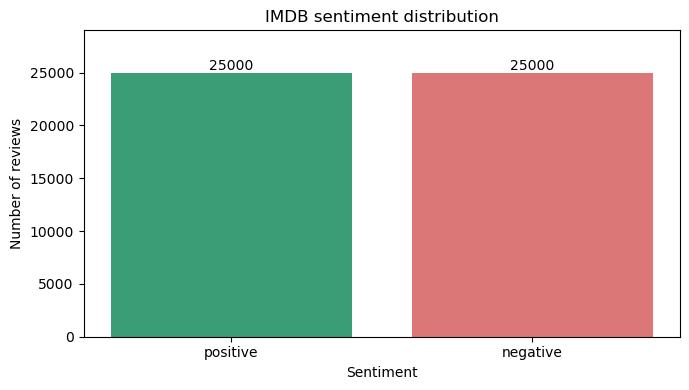

Balanced classes: True


In [17]:
label_counts = df["sentiment"].value_counts().reindex(["positive", "negative"])
display(pd.DataFrame({"count": label_counts, "percentage": (100 * label_counts / len(df)).round(2)}))
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(label_counts.index, label_counts.values, color=["#3a9d75", "#db7777"])
ax.bar_label(bars)
ax.set(title="IMDB sentiment distribution", xlabel="Sentiment", ylabel="Number of reviews", ylim=(0, 29000))
plt.tight_layout(); plt.show()
print("Balanced classes:", label_counts.nunique() == 1)

### 5.Review Length Distribution
Here, I calculated the length of each review using word count. The distribution of review lengths is compared for positive and negative reviews using a histogram and boxplot.

word_count                         character_count                 \
                mean median    std min   max            mean median     std   
sentiment                                                                     
negative       229.5  174.0  164.9   4  1522          1294.1  973.0   945.9   
positive       232.8  172.0  177.5  10  2470          1324.8  968.0  1031.5   

                      
          min    max  
sentiment             
negative   32   8969  
positive   65  13704

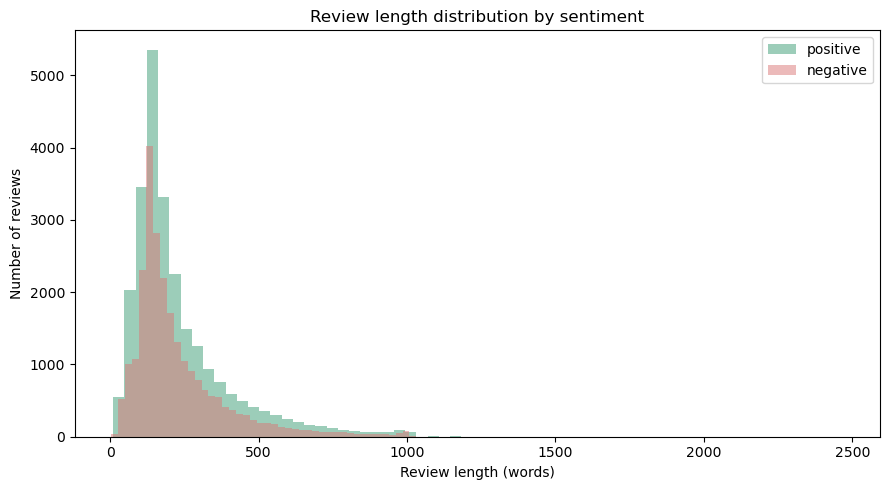

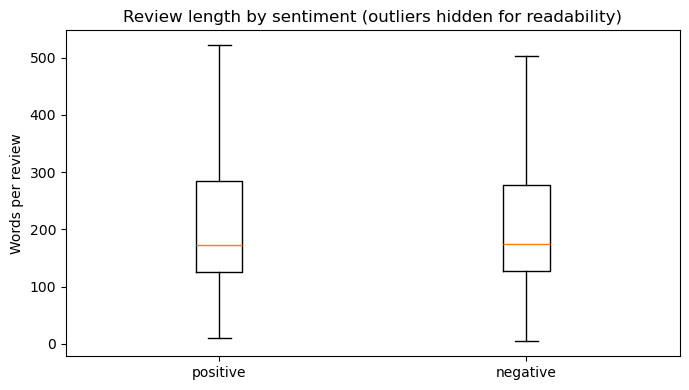

Mean review length: negative=229.5 words, positive=232.8 words
Longer on average: positive


In [18]:
df["word_count"] = df["review"].str.split().str.len()
df["character_count"] = df["review"].str.len()
summary = df.groupby("sentiment")[["word_count", "character_count"]].agg(["mean", "median", "std", "min", "max"]).round(1)
display(summary)
fig, ax = plt.subplots(figsize=(9, 5))
for label, color in [("positive", "#3a9d75"), ("negative", "#db7777")]:
    ax.hist(df.loc[df.sentiment == label, "word_count"], bins=65, alpha=0.5, label=label, color=color)
ax.set(xlabel="Review length (words)", ylabel="Number of reviews", title="Review length distribution by sentiment")
ax.legend(); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([df.loc[df.sentiment == label, "word_count"] for label in ["positive", "negative"]], tick_labels=["positive", "negative"], showfliers=False)
ax.set(title="Review length by sentiment (outliers hidden for readability)", ylabel="Words per review")
plt.tight_layout(); plt.show()
means = df.groupby("sentiment")["word_count"].mean()
print(f"Mean review length: negative={means['negative']:.1f} words, positive={means['positive']:.1f} words")
print("Longer on average:", means.idxmax())

### 6. Checking Duplicate Reviews
Some reviews may appear more than once in the dataset. Here, I checked for duplicate review text and also checked whether any duplicate reviews have different sentiment labels.

In [19]:
full_row_duplicates = int(df.duplicated(subset=["review", "sentiment"]).sum())
review_duplicates = int(df.duplicated(subset=["review"]).sum())
review_counts = df.groupby("review", sort=False).size()
conflicting = df.groupby("review", sort=False)["sentiment"].nunique()
conflicting_texts = int((conflicting > 1).sum())
print("Duplicate full rows (after first occurrence):", full_row_duplicates)
print("Repeated review text (after first occurrence):", review_duplicates)
print("Distinct repeated review texts:", int((review_counts > 1).sum()))
print("Review texts with conflicting labels:", conflicting_texts)
print("Largest identical-review group:", int(review_counts.max()))
if review_duplicates:
    repeated_examples = df[df["review"].duplicated(keep=False)].copy()
    display(repeated_examples[["review", "sentiment"]].assign(review=lambda x: x["review"].str.slice(0, 160)).head(6))

Duplicate full rows (after first occurrence): 418
Repeated review text (after first occurrence): 418
Distinct repeated review texts: 406
Review texts with conflicting labels: 0
Largest identical-review group: 5


,review,sentiment
42,"Of all the films I have seen, this one, The Ra...",negative
84,"We brought this film as a joke for a friend, a...",negative
140,"Before I begin, let me get something off my ch...",negative
219,Ed Wood rides again. The fact that this movie ...,negative
245,I have seen this film at least 100 times and I...,positive
480,From director Barbet Schroder (Reversal of For...,negative


### 7. Checking Raw Reviews and HTML Tags
Five raw reviews are displayed below to check the original review text. Some reviews contain HTML tags such as <br />, which will need to be removed during preprocessing.

In [20]:
html_mask = df["review"].str.contains(
    r"<br\s*/?>", regex=True, case=False, na=False
)

print("Reviews containing <br /> style tags:",
      int(html_mask.sum()))

# Select 3 reviews containing HTML tags
html_indices = df.index[html_mask].tolist()[:3]

# Select 2 other reviews
other_indices = [
    i for i in df.index if i not in html_indices
][:2]

selected_indices = html_indices + other_indices

# Display 5 raw reviews
for number, idx in enumerate(selected_indices, 1):
    row = df.loc[idx]

    print("\n" + "=" * 70)
    print(f"RAW REVIEW {number}")
    print("Sentiment:", row["sentiment"])
    print("=" * 70)
    print(row["review"])

print("\nObservation: HTML tags such as <br /> are visible in the raw reviews.")

Reviews containing <br /> style tags: 29200

RAW REVIEW 1
Sentiment: positive
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never 

### 8. Stratified Train-Test Split
The dataset is divided into 40,000 training reviews and 10,000 testing reviews. Stratified splitting is used to maintain the same proportion of positive and negative reviews in both sets. The test set will be kept separate and will not be used during training or model tuning.

In [21]:
from collections import defaultdict

# Work only with the two original columns. Group IDs are based on exact review text.
raw = df[["review", "sentiment"]].reset_index(drop=True)
groups = raw.groupby("review", sort=False).indices
rng = np.random.default_rng(RANDOM_STATE)
selected_test = []

for label in ["positive", "negative"]:
    candidates = []
    for text_value, indices in groups.items():
        idx = np.asarray(indices, dtype=int)
        labels_in_group = raw.iloc[idx]["sentiment"].unique()
        if len(labels_in_group) == 1 and labels_in_group[0] == label:
            candidates.append(idx)
    # Shuffle entire groups reproducibly, then select groups that fit.
    order = rng.permutation(len(candidates))
    remaining = 5000
    chosen = []
    for j in order:
        group_idx = candidates[j]
        if len(group_idx) <= remaining:
            chosen.extend(group_idx.tolist())
            remaining -= len(group_idx)
        if remaining == 0:
            break
    if remaining:
        raise RuntimeError(f"Could not create an exact 5,000-row test class for {label}; {remaining} rows unfilled. Inspect duplicate groups.")
    selected_test.extend(chosen)

test_indices = np.array(selected_test, dtype=int)
train_mask = np.ones(len(raw), dtype=bool)
train_mask[test_indices] = False
train_df = raw.loc[train_mask].reset_index(drop=True)
test_df = raw.iloc[test_indices].reset_index(drop=True)

assert len(train_df) == 40_000 and len(test_df) == 10_000
assert train_df["sentiment"].value_counts().to_dict() == {"positive": 20_000, "negative": 20_000}
assert test_df["sentiment"].value_counts().to_dict() == {"positive": 5_000, "negative": 5_000}
assert set(train_df["review"]).isdisjoint(set(test_df["review"])), "Duplicate review text crossed the split!"
assert set(train_df.columns) == {"review", "sentiment"}
print("Training set:", len(train_df), "reviews")
print("Test set:", len(test_df), "reviews")

print("\nTraining class balance:")
print(train_df["sentiment"].value_counts())

print("\nTest class balance:")
print(test_df["sentiment"].value_counts())

print("\nIdentical review texts shared across splits: 0")

Training set: 40000 reviews
Test set: 10000 reviews

Training class balance:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

Test class balance:
sentiment
positive    5000
negative    5000
Name: count, dtype: int64

Identical review texts shared across splits: 0


### 9. Saving the Train and Test Sets
The training and testing sets are saved separately so that the test set remains unused until the final evaluation phase.

In [22]:
output_dir = Path("data/splits")
output_dir.mkdir(parents=True, exist_ok=True)
train_path = output_dir / "train.csv"
test_path = output_dir / "test.csv"

# Guard against accidentally overwriting an earlier holdout with a different split.
if train_path.exists() or test_path.exists():
    if not (train_path.exists() and test_path.exists()):
        raise FileExistsError("Only one split file exists. Investigate before overwriting.")
    old_train = pd.read_csv(train_path)
    old_test = pd.read_csv(test_path)
    if not (old_train.equals(train_df) and old_test.equals(test_df)):
        raise FileExistsError("Existing split differs! Keep the original protected test set; do not regenerate it.")
    print("Existing identical split found; no overwrite needed.")
else:
    train_df.to_csv(train_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Saved train and protected test CSVs.")

metadata = {
    "phase": "A", "seed": RANDOM_STATE, "train_rows": 40000, "test_rows": 10000,
    "train_positive": 20000, "train_negative": 20000,
    "test_positive": 5000, "test_negative": 5000,
    "duplicate_review_rows_after_first": review_duplicates,
    "conflicting_label_review_texts": conflicting_texts,
    "duplicate_policy": "Retain all original rows; identical review text cannot cross train/test boundary.",
    "test_usage": "Locked until Phase D; no training, tuning, or preprocessing decisions on test data."
}
metadata_path = Path("split_metadata.json")
if metadata_path.exists():
    assert json.loads(metadata_path.read_text(encoding="utf-8")) == metadata, "Existing split metadata differs."
else:
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Split metadata saved:", metadata_path)
print("PHASE A COMPLETE. Next: Phase B baseline using data/splits/train.csv ONLY.")

Existing identical split found; no overwrite needed.
Split metadata saved: split_metadata.json
PHASE A COMPLETE. Next: Phase B baseline using data/splits/train.csv ONLY.
